# Every opt-in, and how to turn it on

The v3.5 engine reproduces stock UIOOPS v3.5, so anything that changes what it computes or
writes is **off unless you turn it on**. Each is a parameter that defaults to off, and this notebook is where they are named, grouped
by where you turn them on:

1. the `[enhancements]` table of a run configuration (UIOOPS corrections and additions);
2. the same table for the SODA-2 lineage;
3. the v3.5 engine's borrowed combine (`[combine]`, a flag, a keyword);
4. command-line switches of `arrayprobe` and `scripts/run_flight.py`;
5. keyword switches in the Python API that default to `False`.

Every name below is checked against the code when the cell runs -- a stale name raises -- and
`tests/test_every_opt_in_is_in_a_notebook.py` fails when an opt-in the code
declares is named in no example notebook.

**Before this:** [06_read_products](../1_getting_started/06_read_products.ipynb) (Reading the output files). **Next:** [09_enhancement_ab](09_enhancement_ab.ipynb). **Needs:** `pip install "arrayprobe[extra,zarr]"` (matplotlib, xarray) (the enhancements package adds optional sections).

This notebook reads files from the arrayprobe source repository, so run it from a clone of that repository; `pip install arrayprobe` alone does not include them.

## 1. UIOOPS corrections and additions: `[enhancements]`

One table, read the same way by the port (`arrayprobe`, `scripts/run_flight.py`) and by the
`arrayprobe-enhancements` package: **nothing** is on that the file does not name `true`
(`all = true` selects every module applicable to the engine). The enhancements package also
refuses a module that does not apply to the engine you run (four modules correct defects the
UIOOPS developers fixed in v3.5). The table below names every enhancement this installation can run, so it is a
template: flip a line to `true` to opt in.

Check that the notebook is running from the repository root, and import what it needs.

In [1]:
# Launch guard: the cells below reach scripts/ and tests/data/ relative to the repository root.
from pathlib import Path

if not (Path("scripts").is_dir() and Path("tests/data").is_dir()):
    raise RuntimeError(
        f"This notebook must run with the repository root as its working directory, not {Path.cwd()}. "
        "Jupyter starts a kernel in the notebook's own folder (examples/2_processing/), so run "
        "`%cd ../..` in a new cell, then run this cell again. "
        "Headless, from the repository root: python scripts/execute_example_notebooks.py --check <name>"
    )

import sys
import tempfile
from pathlib import Path

from arrayprobe.config import load_config

Write the `[enhancements]` table, first half. It names every enhancement and sets each to `false`, except `spot_edge_fix`, which is on: it restores a missing decimal point in one entry of the Korolev correction table (`calculate_reject_unified.m:53` in v3.5), and it applies on the v3.5 engine this notebook runs.

In [2]:
ENHANCEMENTS_TABLE = """
[enhancements]
analysis = false
arco_export = false
arm_export = false
brown_francis_1995 = false
cf_export = false
diode_range_fix = false
distance_rejection = false
dmax_sensitivity = false
effective_density = false
field2006_shatter = false
hole_edge_swap = false
"""

Second half of the table.

In [3]:
ENHANCEMENTS_TABLE += """int16_double_fix = false
int_arr_rollback_fix = false
intarr_policy = false
intarr_threshold_fix = false
mask_presence_fix = false
md_relations = false
ml_accept_reject = false
outoffocus = false
overload_accounting_fix = false
partial_image_habit = false
particle_clustering = false
particle_number_all_fix = false
particle_time_glitch_fix = false
particle_time_int8_fix = false
pms_c6_routing_fix = false
poisson_restore = false
poisson_uncertainty = false
probe_crossover = false
probe_uncertainty = false
published_dof = false
reshape_fix = false
rollover_fix = false
spec_artefact_filter = false
spot_edge_fix = true
tas_grid_fix = false
"""

Save the table beside a `[fidelity]` profile and load it with the port's configuration reader. The port reports whether two of the enhancements are on.

In [5]:
tmp = Path(tempfile.mkdtemp(prefix="arrayprobe_opt_ins_"))
cfg_path = tmp / "run.toml"
cfg_path.write_text('[fidelity]\nprofile = "stock-v3.5"\n' + ENHANCEMENTS_TABLE)
cfg = load_config(cfg_path)

print(f"the port: spot_edge_fix on? {cfg.enabled('spot_edge_fix')}   "
      f"diode_range_fix on? {cfg.enabled('diode_range_fix')}")

the port: spot_edge_fix on? True   diode_range_fix on? False


Check the table against the `arrayprobe-enhancements` package. Every name in the table must be a name the package knows. With an empty table, no enhancement should be on.

In [6]:
try:
    from arrayprobe_enhancements import registry
except ImportError:
    registry = None
    print("arrayprobe-enhancements is not installed: pip install arrayprobe-uiops-enhancements")
if registry is not None:
    named = set(cfg.enhancements)
    # Repairs that need the validation engine (not part of this package) are not in this
    # package's table.
    validation_only = {k for k, spec in registry.REGISTRY.items() if spec.requires_v314}
    shipped = set(registry.REGISTRY) - validation_only
    assert named - validation_only == shipped, sorted((named - validation_only) ^ shipped)
    assert named & validation_only in (set(), validation_only), sorted(validation_only - named)
    for engine in ("3.5",):
        defaults = registry.resolve({}, engine=engine)
        print(f"arrayprobe-enhancements, engine {engine}: "
              f"{sum(defaults.values())} of {len(defaults)} on with no [enhancements] table")

arrayprobe-enhancements, engine 3.5: 0 of 42 on with no [enhancements] table


## 2. SODA-2 corrections: `[enhancements]` in a `[run] engine = "soda2"` file

Same shape, separate package (`arrayprobe-soda2-enhancements`, in `enhancements_soda2/`),
separate registry, no engine matrix. **Its default is the opposite of the UIOOPS package's**:
a SODA-2 correction is ON unless named `false` (the cell below prints how many resolve on
with no table). `arrayprobe soda2 enhancements CONFIG` prints how a file resolves; the table
names every correction, so setting all of them `false` gives the unmodified engine.

In [7]:
import importlib
import pkgutil

SODA2_ENHANCEMENTS_TABLE = """
[enhancements]
aspr_nan_fix = false
blank_roi_dof_fix = false
den_clamp_fix = false
dilation_clamp_fix = false
double_pi_fix = false
empty_roi_diodegaps_fix = false
fillholes_int_labels = false
hk_probeid_columns = false
label_blobs_int_count = false
last_buffer_index_fix = false
no_stuck_diode_fix = false
pbp_inttime_consistent = false
pbp_rejectionflag_ubyte = false
poisson_fill_guard = false
rejection_tally_fix = false
rollover_modulus_fix = false
run_diagnostics = false
same_time_buffer_fix = false
zero_area_return_fix = false
"""

Import the SODA-2 corrections package and check the table above against its registry.

In [8]:
try:
    import arrayprobe_soda2_enhancements as soda2_enh
except ImportError:  # not installed: use the repository's source tree if it is here
    if Path("../enhancements_soda2/src").is_dir():
        sys.path.insert(0, "../enhancements_soda2/src")
    try:
        import arrayprobe_soda2_enhancements as soda2_enh
    except ImportError:
        soda2_enh = None
        print("arrayprobe-soda2-enhancements is not installed: pip install arrayprobe-soda2-enhancements")
if soda2_enh is not None:
    # Each correction registers itself on import, so import them all before reading REGISTRY.
    for mod in pkgutil.iter_modules(soda2_enh.__path__):
        if mod.name != "registry" and not mod.name.startswith("_"):
            importlib.import_module(f"arrayprobe_soda2_enhancements.{mod.name}")
    from arrayprobe_soda2_enhancements import registry as soda2_registry
    import tomllib
    table = tomllib.loads(SODA2_ENHANCEMENTS_TABLE)["enhancements"]
    assert set(table) == set(soda2_registry.REGISTRY), sorted(set(table) ^ set(soda2_registry.REGISTRY))
    print(f"with no table: {sum(soda2_registry.resolve({}).values())} of "
          f"{len(soda2_registry.REGISTRY)} on; with the table above: "
          f"{sum(soda2_registry.resolve(table).values())} on")

with no table: 0 of 19 on; with the table above: 0 on


## 3. The v3.5 engine's borrowed combine

`combine_sizedist.m` is in no stock UIOOPS release -- it comes from one field campaign's modified tree -- so the v3.5
engine runs it only when asked, and labels the result as borrowed. Three ways to ask, one per
entry point: `[combine]` `borrowed = true` in a run configuration, `--borrowed-combine` on
`scripts/run_flight.py`, and `borrowed_combine=True` to `arrayprobe_uiops.combine.combine_sizedist`.

In [9]:
import inspect

from arrayprobe_uiops.combine import combine_sizedist

cfg_path.write_text('[fidelity]\nprofile = "stock-v3.5"\n[combine]\nborrowed = true\n')
print(f"[combine] borrowed = true  ->  RunConfig.borrowed_combine = "
      f"{load_config(cfg_path).borrowed_combine}")
default = inspect.signature(combine_sizedist).parameters["borrowed_combine"].default
print(f"combine_sizedist(..., borrowed_combine=True): default is {default}")

[combine] borrowed = true  ->  RunConfig.borrowed_combine = True
combine_sizedist(..., borrowed_combine=True): default is False


## 4. Command-line switches

Two of these do something the others do not: they add a *file* rather than changing how an
existing one is computed. Both default off, both on `scripts/run_flight.py`.

- **`--enhancements`** applies the corrections named in `--config`'s `[enhancements]` table to
  the products the run has just written, each into its own `.enh.*` file beside the faithful
  one, with a `.enhancements.json` sidecar recording what was applied and what was skipped and
  why. The port's own output is untouched. **The table alone does nothing** -- naming 33
  corrections in the config and omitting this flag applies none of them, and the run says
  `ALL DONE` without mentioning it, a mistake that has cost a wasted relaunch.
- **`--area-ratio-z`** replaces the size-distribution `'z'` reject threshold for one run, on
  either engine. On v3.5 it replaces the literal `.2` at `sizeDist.m:1162`, takes a value in
  `[0, 1]`, and `0` turns the gate off. It is written to the sd `.call` stamp only when given,
  so an sd built without it keeps its stamp, and with it unset the output is bit-identical.
  The Python keyword is `area_ratio_z=` on `arrayprobe_uiops.sizedist.run` (section 5).
- **`--enh-jobs N`** (default 1, serial) spreads the enhancement pass's out-of-focus loop over
  N worker processes. It only matters together with `--enhancements`, and is accepted by both
  `arrayprobe run` and `scripts/run_flight.py`, e.g. `arrayprobe run ... --enhancements --enh-jobs 4`
  (shown here as a command string; nothing in this notebook runs it against real data).
- **`--write-provenance`** writes the full provenance record for a run. It refuses to combine
  with `--engine 3.5` and with `--chunks`/`--jobs`, so it is a single-process v3.1.4 tool; the
  driver says so and exits 2 rather than writing a partial record.
- **`--accept-implausible`** overrides the plausibility gate that runs after the
  size-distribution stage. The gate refuses an sd in which no second, or under 0.1 % of
  seconds, carries particles while its `proc` accepted some -- the usual causes are a particle
  clock never shifted to the airspeed clock, or a bin table that does not match the probe. The
  file is kept either way; the flag only lets the run treat it as current, and it is written
  as `accept_implausible=on` into the sd `.call` stamp, so an overridden product is never
  mistaken for one that passed. Use it only once you have checked why the file is empty.
- **`--accept-preset-mismatch`** runs a raw file whose extension names a different probe from
  the preset (for example `.HVPS` under a 2D-S preset), which the driver otherwise refuses before
  decoding; the run's stamp records the override.

Each one below is off unless given. The speed switches `--jobs`, `--s2-jobs` and `--chunks`
default to 1 (serial) and are byte-identical to it -- tests assert
that. `--jit` (the image-processing stage's hot kernels through numba,
needs the `jit` optional dependency, numba) is speed only too: a test asserts
the `proc` file is byte-identical. `--quiet` and `--verbose`, given before the subcommand, set
how much library logging the console script shows. `--dense` on `make-demo-flight` writes the DENSE demo flight instead of the sparse one -- not speed, but the switch that decides whether the quickstart's size distribution comes out populated or empty; `--with-config` on the same command writes a ready-to-run `run.toml` beside the flight, so the quickstart needs no repository checkout. The cell reads each switch's default and help
from the real parser, so a renamed or removed switch raises here. `--yes` is the one switch here that turns nothing on: a run that names no threshold policy prints its whole configuration and asks before starting, and where stdin is not a terminal -- every detached run -- it refuses to start without `--yes` rather than blocking on a prompt nobody can answer. Declaring `[thresholds]` in the config file is the better answer and skips the gate entirely.

The demo-flight generator has one switch of its own. `arrayprobe make-demo-flight --distinct-counters`
(in Python, `build_dense_demo_flight(path, distinct_counters=True)`) gives each image packet its own
particle counter, so the SODA-2 engine, which keeps a frame only when the counter changes, reads every
particle of the demo file rather than the first. Off by default, which writes the same bytes as before.

In [10]:
import contextlib
import io

sys.path.insert(0, "scripts")
import run_flight  # noqa: E402
from arrayprobe.cli import build_parser  # noqa: E402

SWITCHES = {
    "arrayprobe": ["--quiet", "--verbose"],
    "arrayprobe run": ["--jobs", "--s2-jobs", "--chunks", "--jit", "--dry-run", "--yes",
                      "--enh-jobs"],
    "arrayprobe intarr-threshold": ["--fix-b8"],
    "arrayprobe compare": ["--verbose", "--classes"],
    "arrayprobe gallery": ["--no-crop", "--no-index"],
    "arrayprobe engines": ["--catalogue"],
    "arrayprobe make-demo-flight": ["--dense"],
    "arrayprobe tas-from-nasa-ames": ["--drop-missing"],
    "scripts/run_flight.py": ["--jobs", "--s2-jobs", "--chunks", "--dry-run", "--diode-corrected",
                            "--accept-unstamped", "--enhancements", "--write-provenance", "--allow-mixed-config", "--borrowed-combine", "--jit",
                            "--resume-chunks", "--tas-from-probe", "--yes", "--area-ratio-z",
                            "--enh-jobs", "--accept-implausible"],
}

Define the helpers that read each command's help text and pick out one switch's description.

In [12]:
def help_text(command):
    buf = io.StringIO()
    with contextlib.redirect_stdout(buf), contextlib.suppress(SystemExit):
        if command == "scripts/run_flight.py":
            run_flight.main(["--help"])
        elif command == "arrayprobe":
            build_parser().parse_args(["--help"])
        else:
            build_parser().parse_args([command.split()[1], "--help"])
    return buf.getvalue()


def describe(help_, flag):
    lines = help_.splitlines()
    start = next(i for i, ln in enumerate(lines) if ln.strip().split(" ")[0].rstrip(",") in
                 (flag, "-v", "-y") and flag in ln)
    block = [lines[start].strip()]
    for ln in lines[start + 1:]:
        if ln.startswith("  -") or not ln.startswith("    "):  # the next switch, or the end
            break
        block.append(ln.strip())
    return " ".join(block)

Print the description of every switch in the list.

In [13]:
for command, flags in SWITCHES.items():
    help_ = help_text(command)
    print(command)
    for flag in flags:
        print(f"  {describe(help_, flag).split(' Engine ')[0][:150]}")

arrayprobe
  --quiet               suppress informational/warning library logging (errors still show); does not affect a subcommand's own print() output.
  --verbose             show DEBUG-level library logging in addition to the default INFO/WARNING messages.
arrayprobe run
  --jobs N              process N raw files at once, one worker process each (default 1). Helps a flight recorded as many files; outputs are the same as
  --s2-jobs N           decode one raw file across N worker processes (default 1). Helps a flight recorded as one large file, where --jobs has nothing t
  --chunks N            split each file's image processing (particle framing) into N record ranges run in parallel and merged (default 1); the merged fi
  --jit                 speed only, default off: the image-processing stage's hot kernels through numba (arrayprobe.jit_kernels); the proc file is byte-
  --dry-run             preflight only, decode nothing
  --yes, -y             accept the configuration this pri

The same data in xarray, which most earth-science tools read:

<xarray.Dataset> Size: 1kB
Dimensions:      (entry_point: 9)
Coordinates:
  * entry_point  (entry_point) int64 72B 0 1 2 3 4 5 6 7 8
    command      (entry_point) <U29 1kB 'arrayprobe' ... 'scripts/run_flight.py'
Data variables:
    n_switches   (entry_point) int64 72B 2 7 1 2 2 1 1 1 17


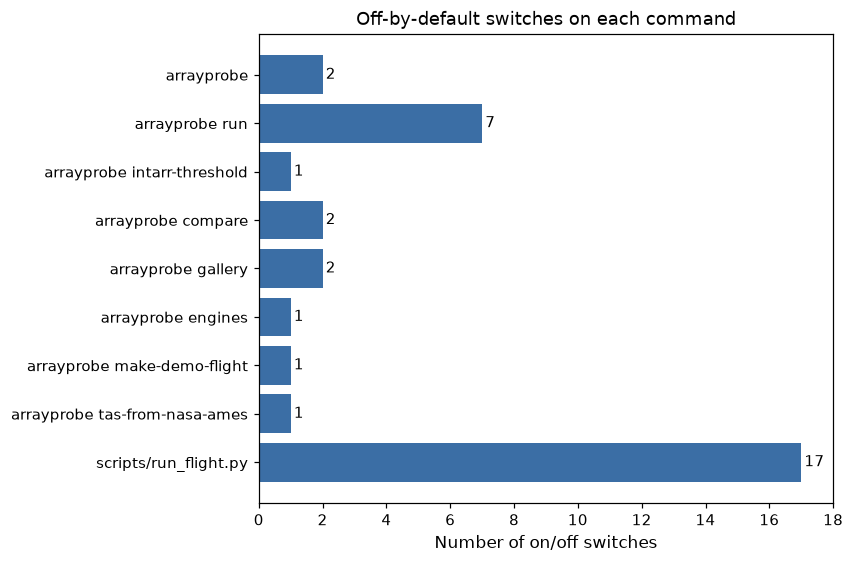

In [14]:
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr

labels = list(SWITCHES)
switches = xr.Dataset(
    {"n_switches": ("entry_point", [len(SWITCHES[c]) for c in labels])},
    coords={"entry_point": np.arange(len(labels)), "command": ("entry_point", labels)},
)
print(switches)

fig, ax = plt.subplots(figsize=(8, 0.45 * len(labels) + 1.2))
counts = switches["n_switches"].values
ax.barh(labels, counts, color="#3b6ea5")
ax.invert_yaxis()
ax.set_xlabel("Number of on/off switches", fontsize=11)
ax.xaxis.get_major_locator().set_params(integer=True)
ax.tick_params(labelsize=10)
for y, n in enumerate(counts):
    ax.text(n + 0.1, y, str(n), va="center", fontsize=10)
ax.set_xlim(0, counts.max() + 1)
ax.set_title("Off-by-default switches on each command", fontsize=12)
fig.tight_layout()
plt.show()

*Figure 1. How many off-by-default switches each command offers. `arrayprobe run` and `scripts/run_flight.py` carry most of them; every other command has one or two.*

## 5. Keyword switches in the Python API

Every public keyword argument in the port packages that defaults to `False`, with the line of
its function's own docstring that mentions it (or the docstring's first line). Pass `=True` to
turn one on. One entry defaults to `None` instead and takes a value:
`arrayprobe_uiops.sizedist.run(area_ratio_z=0.5)` replaces the literal `.2` at `sizeDist.m:1162`
for that call (`0.0` turns the gate off); left `None` the call is bit-identical to stock v3.5.

**One keyword in this inventory is not a switch you should flip**, and it is named here so that
nobody mistakes it for one. `arrayprobe_uiops.imgproc`'s probe specification takes
`image_invert=False` (the default), but the value is **a per-probetype constant, not a
preference**: the three shipped probe tables set it `False` for PMS, `False` for DMT and `True`
for SPEC (`:224`, `:227`, `:231`), reproducing the original's `:785-795`. The PMS and DMT raw
formats already store 1 = illuminated, so inverting them would be wrong, not optional. You would
pass it only when defining a probe specification of your own, and then its value is dictated by
your probe's format rather than chosen. `accept_unstamped=True` on the attributed export is the one here that loosens a refusal rather than adding a behaviour: the exporter refuses a product with no `.call` sidecar, because a self-describing file built on unknown provenance is worse than no file. With the flag it exports and **records the gap in the file itself** rather than leaving it blank.

`exact_sync=True` on the DMT and SEA readers (`read_binary_DMT`, `read_binary_DMT_parallel`, `read_binary_SEA`) makes the record-boundary search accept only the byte `0xAA`. MATLAB compares the byte's high hex digit alone, so every byte `0xA0`-`0xAF` counts as a sync byte; that is the default, and the reason a stray `0xA3` before the sentinel can lock the slice grid one byte early.

`stray_pixel_fix=True` on `arrayprobe_uiops.imgproc.imgproc_sm_v35` removes isolated stray pixels from each particle image before its geometry is measured. The keyword defaults to `False`, but the batch driver turns the correction **on by default for engine 3.5**; switch it off with `--stray-pixel off` or `stray_pixel_fix = false` under `[enhancements]`. Before-and-after images: [`04_stray_pixel_images.ipynb`](../5_data_quality/04_stray_pixel_images.ipynb).

`zero_sv_nan=True` on `arrayprobe_uiops.sizedist.run` writes NaN, not Inf, as the concentration of a second whose sample volume is zero (a probe overload of exactly one second leaves no live time, so every count is divided by zero). The keyword defaults to `False`, which reproduces stock v3.5; the batch driver turns it **on by default for engine 3.5**. `sample_vol` itself is written unchanged, so the zero is still visible. The cell after the inventory shows the arithmetic on a synthetic second; [`03_comparing_processing_chains_in_db.ipynb`](../7_analysis_and_outputs/03_comparing_processing_chains_in_db.ipynb) shows why a non-finite second matters when two products are compared.

In [15]:
import importlib
import importlib.util

KEYWORD_SWITCHES = [
    ("arrayprobe.intarr_analysis", "analyse", "collect_histograms=True"),
    ("arrayprobe.intarr_analysis", "overlay_time_axis", "fix_b8=True"),
    ("arrayprobe.readers.dmt", "read_binary_DMT", "exact_sync=True"),
    ("arrayprobe.readers.dmt", "read_binary_DMT_parallel", "exact_sync=True"),
    ("arrayprobe.readers.sea", "read_binary_SEA", "exact_sync=True"),
    ("arrayprobe.render", "render_particle", "crop=True"),
    ("arrayprobe.review_sampling", "Sample", "only_accepted=True"),
    ("arrayprobe.compare", "format_report", "verbose=True"),
    ("arrayprobe.tools.make_demo_flight", "run_word", "new_slice=True"),
    ("arrayprobe.tools.make_demo_flight", "image_packet", "timing=True"),
    ("arrayprobe_uiops.combine", "combine_sizedist", "borrowed_combine=True"),
    ("arrayprobe_uiops.sizedist", "run", "octave_colon=True"),
    ("arrayprobe_uiops.sizedist", "run", "octave_mean_extra=True"),
    ("arrayprobe_uiops.spec", "read_binary_spec_v35", "output_txt=True"),
    ("arrayprobe_uiops.imgproc", "imgproc_sm_v35", "jit=True"),
    ("arrayprobe_uiops.particle_physics", "single_vt", "use_mitchell=True"),
    ("arrayprobe.attributed_export", "export", "accept_unstamped=True"),
    ("arrayprobe_soda2.min_circle_fast", "min_circle_fast", "warn_on_cap=True"),
    ("arrayprobe_soda2.spec_index", "spec_index", "lite=True"),
    ("arrayprobe_soda2.spec_index", "spec_index", "absolutepointer=True"),
    ("arrayprobe_soda2.label_blobs", "label_blobs", "all_neighbors=True"),
    ("arrayprobe_soda2.label_blobs", "label_blobs", "integer=True"),
    ("arrayprobe_soda2.aspect_ratio", "aspect_ratio", "coordinates=True"),
    ("arrayprobe_soda2.spec_readint", "spec_readint", "signed=True"),
    ("arrayprobe_soda2.fit_poisson", "fit_poisson", "plot=True"),
    ("arrayprobe_soda2.export_ascii", "mmdiam", "nan=True"),
    ("arrayprobe_soda2.save_writer", "write_idl_save", "compress=True"),
    ("arrayprobe_uiops.imgproc", "imgproc_sm_v35", "stray_pixel_fix=True"),
    ("arrayprobe_uiops.imgproc", "imgproc_sm_v35", "ncar_2dc_timing_fix=True"),
    ("arrayprobe_uiops.sizedist", "run", "area_ratio_z=0.5"),
    ("arrayprobe_uiops.sizedist", "run", "zero_sv_nan=True"),
]

Check that each switch defaults to off and print the line of its function's documentation that names it.

In [17]:
for module, func, call in KEYWORD_SWITCHES:
    kw = call.split("=")[0]
    obj = getattr(importlib.import_module(module), func)
    default = inspect.signature(obj).parameters[kw].default
    # A switch defaults to False and is turned on with =True; the one value-taking opt-in
    # (area_ratio_z) defaults to None, meaning "stock", and is given a number instead.
    assert default is False or (default is None and not call.endswith("True")), (
        module, func, kw, default)
    doc = [ln.strip() for ln in (inspect.getdoc(obj) or "").splitlines() if ln.strip()]
    line = next((ln for ln in doc if kw in ln), doc[0] if doc else "")
    print(f"{module}.{func}({call})\n    {line[:110]}")

arrayprobe.intarr_analysis.analyse(collect_histograms=True)
    ``collect_histograms=False`` (default) leaves this function's return value byte-for-byte
arrayprobe.intarr_analysis.overlay_time_axis(fix_b8=True)
    ``fix_b8=False`` (default, matching every real run of the source) reproduces the upstream
arrayprobe.readers.dmt.read_binary_DMT(exact_sync=True)
    ``exact_sync`` (default ``False``, MATLAB's behaviour) makes the boundary
arrayprobe.readers.dmt.read_binary_DMT_parallel(exact_sync=True)
    :func:`read_binary_DMT` across ``jobs`` processes, byte-identical output.
arrayprobe.readers.sea.read_binary_SEA(exact_sync=True)
    ``exact_sync`` (default ``False``, MATLAB's behaviour) makes the boundary
arrayprobe.render.render_particle(crop=True)
    ``crop`` (default off, so single-particle/CLI use is unaffected): display
arrayprobe.review_sampling.Sample(only_accepted=True)
    A stratified draw over one flight's ``proc`` file.
arrayprobe.compare.format_report(verbose=True)
    R

This cell shows by hand what the zero-sample-volume switch changes. In three seconds of made-up counts the middle second sampled no air, so dividing by its volume gives an undefined value; the cell compares plain division with a version that marks that second as missing, then compares the means over the three seconds.

In [18]:
import numpy as np

# Synthetic: three seconds of counts in two bins; the middle second's sample volume is
# zero (an overload of exactly one second). Same arithmetic as the size-distribution
# stage: concentration = count / sample volume.
counts = np.array([[4.0, 1.0], [3.0, 0.0], [5.0, 2.0]])
sample_vol = np.array([[2.0, 2.0], [0.0, 0.0], [2.5, 2.5]])
with np.errstate(divide="ignore", invalid="ignore"):
    stock = counts / sample_vol                                  # zero_sv_nan=False
    fixed = counts / np.where(sample_vol > 0, sample_vol, np.nan)  # zero_sv_nan=True
print("zero_sv_nan=False:", stock[1], "  zero_sv_nan=True:", fixed[1])
print("mean over seconds, stock:", np.nanmean(stock, axis=0),
      " fixed:", np.nanmean(fixed, axis=0))


zero_sv_nan=False: [inf nan]   zero_sv_nan=True: [nan nan]
mean over seconds, stock: [ inf 0.65]  fixed: [2.   0.65]


### Reading a product written under the old name

`existing_combined_path` finds a combined product in a folder. Older products carry a `_2` suffix; with `legacy_if_missing=True` the function returns that older name when neither file exists yet, so a caller pointing at an older archived product gets the name it was written under. This is a naming option, not a processing one: it changes which file is read, never a number in it. The cell below needs no data, only an empty temporary folder.

In [19]:
import tempfile
from pathlib import Path

from arrayprobe_uiops.decode_naming import existing_combined_path

with tempfile.TemporaryDirectory() as folder:
    current = existing_combined_path(folder, "base160906064017")
    older = existing_combined_path(folder, "base160906064017", legacy_if_missing=True)
    print("default name:          ", Path(current).name)
    print("legacy_if_missing=True:", Path(older).name)

default name:           base160906064017.combined.H.2DS.cdf
legacy_if_missing=True: base160906064017.combined.H.2DS_2.cdf


### Running a raw file the inventory flags as empty

Before any decode the driver reads the raw file's inventory. An empty file is refused, because it would write a product with nothing in it; a file whose last record is cut short only warns. `--accept-flagged` processes a flagged file anyway and logs that it did. Off by default, so a flagged file is never processed silently.

In [20]:
command = ["python", "scripts/run_flight.py", "raw_file.2DS", "--engine", "3.5",
           "--preset", "ORACLES_2016_2DS_H", "--accept-flagged"]
print(" ".join(command))

python scripts/run_flight.py raw_file.2DS --engine 3.5 --preset ORACLES_2016_2DS_H --accept-flagged
